# Problem 4: Fine-Tuning a Text-to-Image Model Using Crowd-Sourced Text–Image Pairs

#### Computer Vision - Assignment - 2 - PS 4
##### Group no 36
| Name      | Roll Number    | Percent |
|-----------|----------------|---------|
| Ashvini Satish Bhosale | 2024aa05732    | 100      |
| Rajesh Talari |2024aa05071| 100     |
|Rahul Agnihotri| 2024aa05347| 100  |
|Pramod T K|2024ab05128|  100           |
|Pagi Sandeep Satish Pratibha|2024aa05545| 100  |

## Presentation Link - https://www.youtube.com/watch?v=erj2E0ejqvw

**Objective**: Fine-tune Stable Diffusion v1.5 with LoRA to generate simple,
readable text images using crowd-sourced text–image pairs.

**Key topics covered**:
1. Domain shift from synthetic to real data
2. Model adaptation using limited, noisy samples
3. Practical constraints of fine-tuning generative models on Colab

**Architecture**: SD v1.5 → freeze base → LoRA on cross-attention layers → `diffusers` + `peft`

**Evaluation**:
- Qualitative: visual clarity, font/spacing realism, background consistency
- Quantitative (mandatory): OCR pipeline → exact string match + character accuracy
- Ablation: base SD vs LoRA fine-tuned

## 1. Environment Setup

In [1]:
!pip install -q diffusers transformers accelerate peft pytesseract huggingface_hub
!sudo apt-get install -y tesseract-ocr > /dev/null 2>&1
print("Done!")

Done!


In [2]:
import os, json, csv, random, warnings
from pathlib import Path
from collections import defaultdict

import numpy as np
import matplotlib
import matplotlib.pyplot as plt
from PIL import Image, ImageDraw, ImageFont, ImageFilter, ImageEnhance

import torch
from torch.utils.data import Dataset, DataLoader
from torchvision import transforms

from diffusers import (
    AutoencoderKL,
    DDPMScheduler,
    StableDiffusionPipeline,
    UNet2DConditionModel,
)
from transformers import CLIPTextModel, CLIPTokenizer
from peft import LoraConfig, PeftModel, get_peft_model

import pytesseract
from difflib import SequenceMatcher

warnings.filterwarnings("ignore")

Flax classes are deprecated and will be removed in Diffusers v1.0.0. We recommend migrating to PyTorch classes or pinning your version of Diffusers.
Flax classes are deprecated and will be removed in Diffusers v1.0.0. We recommend migrating to PyTorch classes or pinning your version of Diffusers.


In [3]:
# --- Reproducibility ---
SEED = 42

def set_seed(seed=42):
    random.seed(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)
    torch.cuda.manual_seed_all(seed)
    torch.backends.cudnn.deterministic = True
    torch.backends.cudnn.benchmark = False

set_seed(SEED)
DEVICE = "cuda" if torch.cuda.is_available() else "cpu"
print(f"Device: {DEVICE}")
if DEVICE == "cpu":
    print("[WARN] CUDA unavailable — training will be extremely slow. Use Colab T4 GPU.")

Device: cuda


## 2. Crowd-Sourced Dataset — Synthetic Generation + Real Subset Support

We generate a synthetic dataset simulating real operational text images (signs,
labels, forms) with realistic noise: rotation, blur, lighting variation, varied
fonts, and backgrounds.

**Real data**: Place your own crowd-sourced images in `real_crowd_subset/` with
a `metadata.json` file. The pipeline merges both domains automatically.

In [4]:
SYNTH_DIR = "crowd_sourced_dataset"
REAL_DIR  = "real_crowd_subset"
os.makedirs(SYNTH_DIR, exist_ok=True)

# Operational text prompts — real-world signage, labels, instructions
TEXT_PROMPTS = [
    "STOP", "EXIT", "DANGER", "OPEN", "CLOSED",
    "HELLO", "WARNING", "ENTER", "PUSH", "PULL",
    "FIRE EXIT", "NO ENTRY", "ONE WAY", "KEEP OUT", "SLOW DOWN",
    "SPEED LIMIT", "PARKING", "CAUTION", "WELCOME", "RESTROOM",
    "EMERGENCY", "DO NOT TOUCH", "PRIVATE", "STAFF ONLY", "FRAGILE",
    "THIS SIDE UP", "HANDLE WITH CARE", "KEEP DRY", "RECYCLE", "QUIET ZONE",
    "NO SMOKING", "WIFI ZONE", "CHECK IN", "GATE A", "PLATFORM 3",
    "BUS STOP", "TAXI", "PHARMACY", "HOSPITAL", "SCHOOL ZONE",
]


def generate_crowd_sourced_image(text, img_size=(512, 512)):
    """
    Simulate a real crowd-sourced photo of operational text with noise,
    rotation, blur, lighting variation, and diverse backgrounds.
    """
    bg_type = random.choice(["solid", "gradient", "noisy"])
    bg_color = tuple(random.randint(150, 255) for _ in range(3))

    img = Image.new("RGB", img_size, bg_color)
    draw = ImageDraw.Draw(img)

    if bg_type == "noisy":
        noise = np.random.randint(0, 40, (*img_size, 3), dtype=np.uint8)
        bg_arr = np.array(img)
        img = Image.fromarray(
            np.clip(bg_arr.astype(int) + noise.astype(int), 0, 255).astype(np.uint8)
        )
        draw = ImageDraw.Draw(img)
    elif bg_type == "gradient":
        tgt = tuple(random.randint(50, 150) for _ in range(3))
        for y in range(img_size[1]):
            r = y / img_size[1]
            c = tuple(int(bg_color[i] * (1 - r) + tgt[i] * r) for i in range(3))
            draw.line([(0, y), (img_size[0], y)], fill=c)

    # Font
    font_size = random.randint(36, 72)
    try:
        candidates = [
            "/usr/share/fonts/truetype/dejavu/DejaVuSans-Bold.ttf",
            "/usr/share/fonts/truetype/liberation/LiberationSans-Bold.ttf",
            "/usr/share/fonts/truetype/dejavu/DejaVuSans.ttf",
            "/usr/share/fonts/truetype/liberation/LiberationMono-Regular.ttf",
        ]
        existing = [p for p in candidates if os.path.exists(p)]
        font = ImageFont.truetype(random.choice(existing) if existing else candidates[0], font_size)
    except Exception:
        font = ImageFont.load_default()

    text_color = tuple(random.randint(0, 80) for _ in range(3))
    bbox = draw.textbbox((0, 0), text, font=font)
    tw, th = bbox[2] - bbox[0], bbox[3] - bbox[1]
    x = (img_size[0] - tw) // 2 + random.randint(-30, 30)
    y = (img_size[1] - th) // 2 + random.randint(-30, 30)
    draw.text((x, y), text, fill=text_color, font=font)

    # Rotation (camera tilt)
    img = img.rotate(random.uniform(-8, 8), fillcolor=bg_color, expand=False)

    # Random blur (focus issues)
    if random.random() < 0.3:
        img = img.filter(ImageFilter.GaussianBlur(radius=random.uniform(0.5, 1.5)))

    # Brightness variation (lighting)
    if random.random() < 0.4:
        img = ImageEnhance.Brightness(img).enhance(random.uniform(0.7, 1.3))

    # JPEG compression artifacts (simulates phone camera saves)
    if random.random() < 0.2:
        from io import BytesIO
        buf = BytesIO()
        img.save(buf, format="JPEG", quality=random.randint(50, 80))
        buf.seek(0)
        img = Image.open(buf).convert("RGB")

    return img


def create_synthetic_dataset(prompts, num_variations=3, output_dir=SYNTH_DIR):
    manifest = []
    for prompt in prompts:
        for v in range(num_variations):
            img = generate_crowd_sourced_image(prompt)
            fname = f"{prompt.replace(' ', '_').lower()}_{v}.png"
            img.save(os.path.join(output_dir, fname))
            manifest.append({
                "file_name": fname,
                "text": prompt,
                "prompt": f'A clear photo of a sign that reads "{prompt}"',
                "domain": "synthetic",
            })
    with open(os.path.join(output_dir, "metadata.json"), "w") as f:
        json.dump(manifest, f, indent=2)
    return manifest


def load_real_subset(data_dir=REAL_DIR):
    meta_path = os.path.join(data_dir, "metadata.json")
    if not os.path.exists(meta_path):
        print(f"[INFO] No real subset at '{meta_path}'. Using synthetic only.")
        return []
    with open(meta_path) as f:
        raw = json.load(f)
    manifest = []
    for row in raw:
        fpath = os.path.join(data_dir, row["file_name"])
        if os.path.exists(fpath):
            manifest.append({
                "file_name": row["file_name"],
                "text": row["text"].strip().upper(),
                "prompt": row.get("prompt", f'A clear photo of a sign that reads "{row["text"]}"'),
                "domain": "real",
            })
    print(f"Loaded {len(manifest)} real crowd-sourced samples from '{data_dir}'")
    return manifest


# --- Build Dataset ---
synthetic_manifest = create_synthetic_dataset(TEXT_PROMPTS, num_variations=3)
real_manifest = load_real_subset()
print(f"Synthetic: {len(synthetic_manifest)} | Real: {len(real_manifest)}")

[INFO] No real subset at 'real_crowd_subset/metadata.json'. Using synthetic only.
Synthetic: 120 | Real: 0


In [5]:
# --- Train / Held-out Split by Unseen Text Labels ---

def split_by_text(synthetic, real, test_ratio=0.25, seed=SEED):
    """Split so held-out set has completely unseen text labels."""
    combined = synthetic + real
    all_texts = sorted({x["text"] for x in combined})
    rng = random.Random(seed)
    rng.shuffle(all_texts)

    n_test = max(2, int(len(all_texts) * test_ratio))
    test_texts = set(all_texts[:n_test])

    train = [x for x in combined if x["text"] not in test_texts]
    test  = [x for x in combined if x["text"] in test_texts]

    test_synth = [x for x in test if x["domain"] == "synthetic"]
    test_real  = [x for x in test if x["domain"] == "real"]

    print(f"Total unique texts: {len(all_texts)}")
    print(f"Held-out texts ({n_test}): {sorted(test_texts)}")
    print(f"Train: {len(train)} | Test-synth: {len(test_synth)} | Test-real: {len(test_real)}")
    return train, {"synthetic_heldout": test_synth, "real_heldout": test_real}, test_texts


train_manifest, test_splits, heldout_texts = split_by_text(synthetic_manifest, real_manifest)

Total unique texts: 40
Held-out texts (10): ['CLOSED', 'DANGER', 'FIRE EXIT', 'FRAGILE', 'GATE A', 'PRIVATE', 'PULL', 'SCHOOL ZONE', 'SPEED LIMIT', 'THIS SIDE UP']
Train: 90 | Test-synth: 30 | Test-real: 0


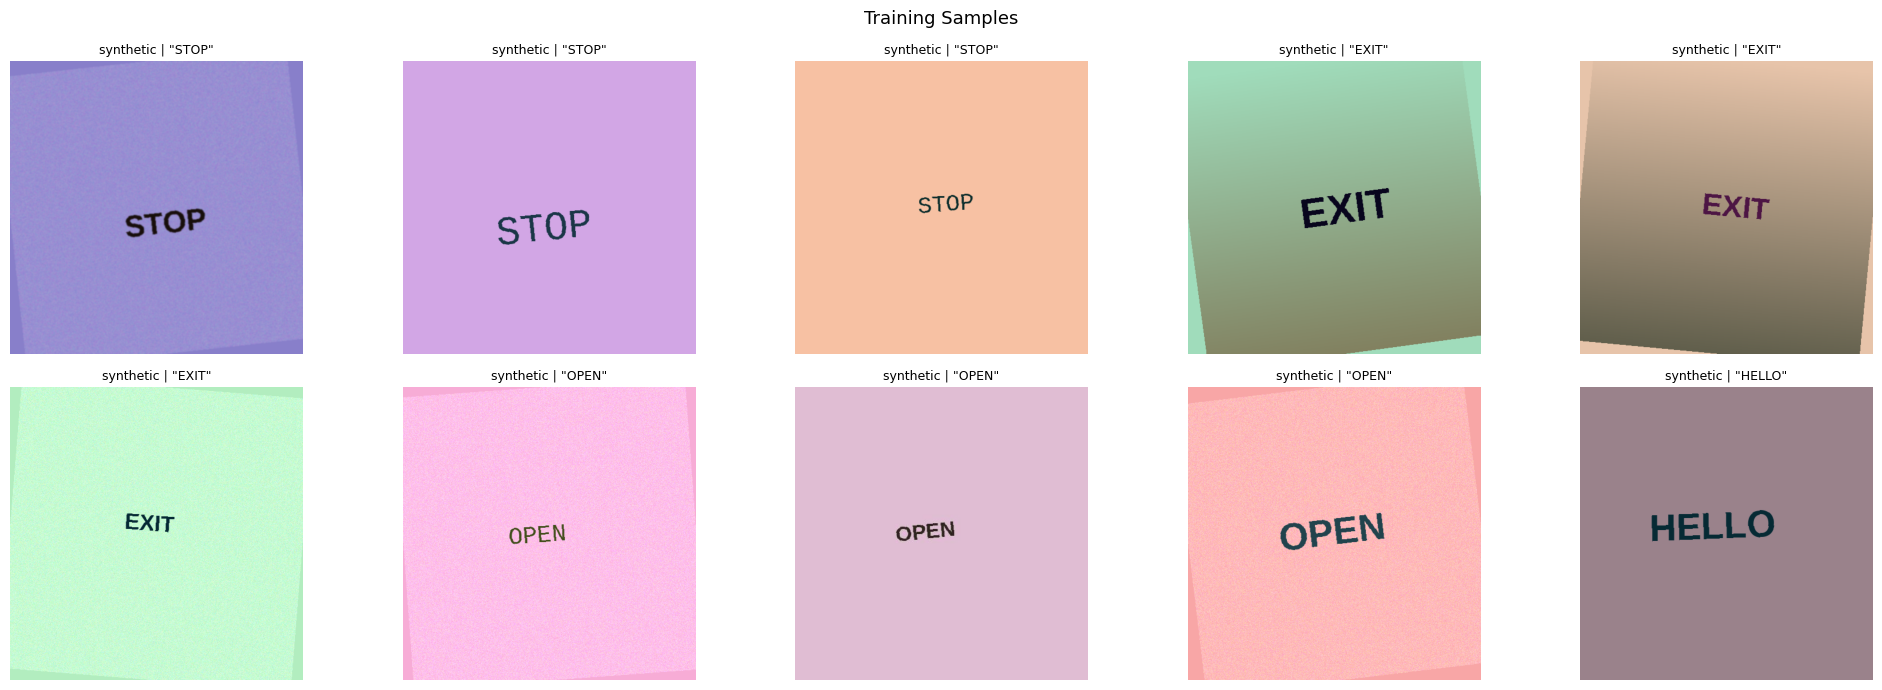

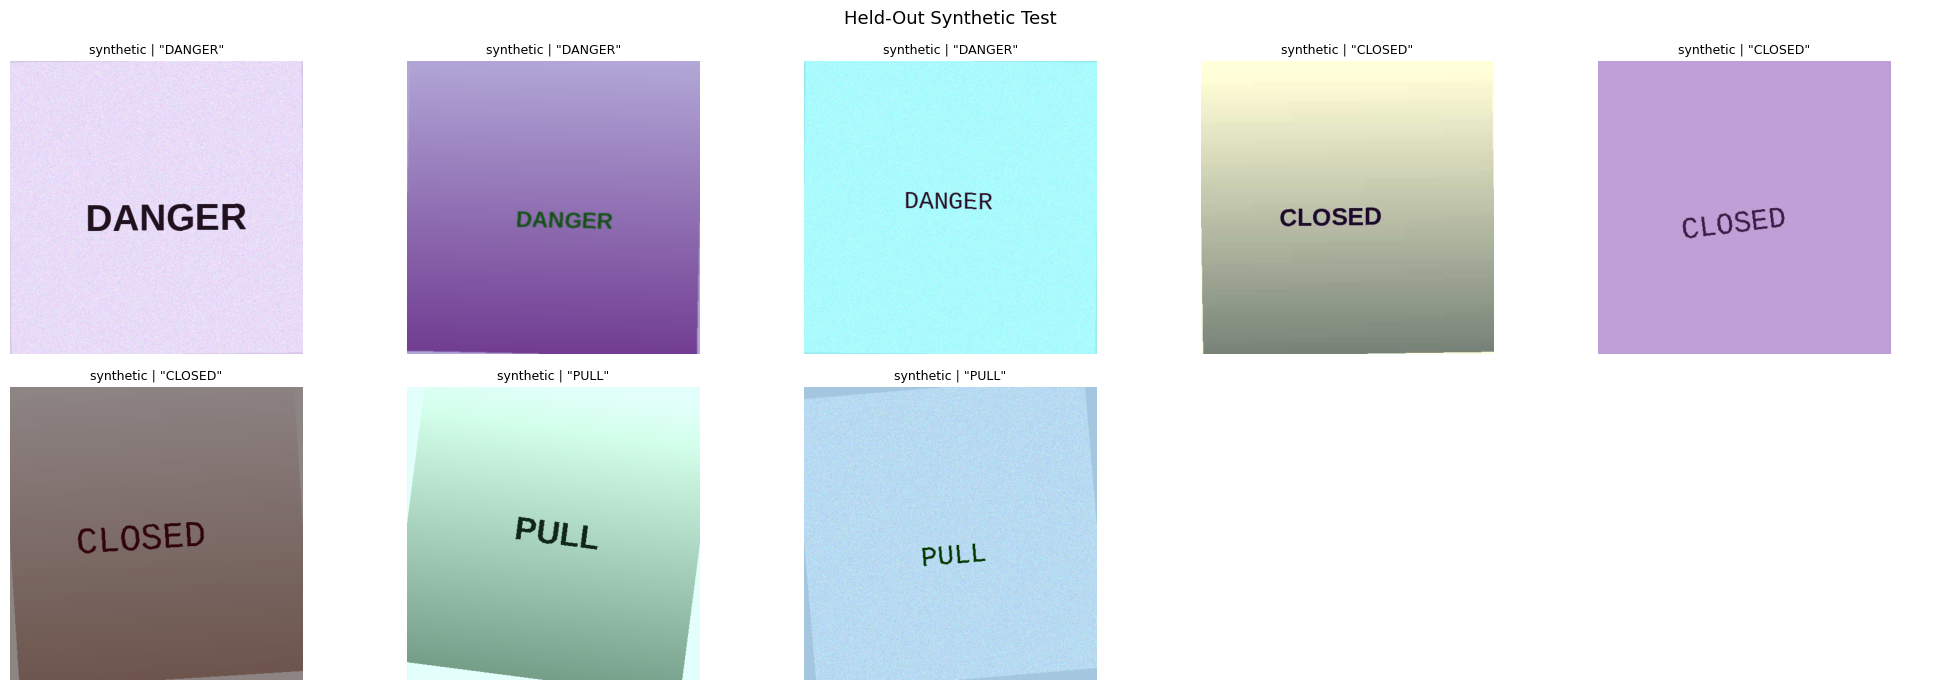

In [6]:
# --- Visualize Training Samples ---
ROOT_DIRS = {"synthetic": SYNTH_DIR, "real": REAL_DIR}

def show_samples(manifest, root_dirs, title, n=10, save_path=None):
    if not manifest:
        print(f"Empty: {title}")
        return
    n = min(n, len(manifest))
    cols = min(5, n)
    rows = max(1, int(np.ceil(n / cols)))
    fig, axes = plt.subplots(rows, cols, figsize=(4 * cols, 3.5 * rows))
    if rows * cols == 1:
        axes = np.array([axes])
    axes = np.array(axes).flatten()
    for i in range(len(axes)):
        axes[i].axis("off")
        if i < n:
            item = manifest[i]
            img = Image.open(os.path.join(root_dirs[item["domain"]], item["file_name"]))
            axes[i].imshow(img)
            axes[i].set_title(f'{item["domain"]} | "{item["text"]}"', fontsize=9)
    plt.suptitle(title, fontsize=13)
    plt.tight_layout()
    if save_path:
        plt.savefig(save_path, dpi=100, bbox_inches="tight")
    plt.show()

show_samples(train_manifest, ROOT_DIRS, "Training Samples", n=10, save_path="dataset_samples_train.png")
if test_splits["synthetic_heldout"]:
    show_samples(test_splits["synthetic_heldout"], ROOT_DIRS, "Held-Out Synthetic Test", n=8, save_path="dataset_samples_test.png")

## 3. PyTorch Dataset & Preprocessing

In [7]:
class TextImageDataset(Dataset):
    def __init__(self, manifest, root_dirs, tokenizer, resolution=512):
        self.manifest = manifest
        self.root_dirs = root_dirs
        self.tokenizer = tokenizer
        self.transform = transforms.Compose([
            transforms.Resize((resolution, resolution)),
            transforms.ToTensor(),
            transforms.Normalize([0.5, 0.5, 0.5], [0.5, 0.5, 0.5]),  # to [-1, 1]
        ])

    def __len__(self):
        return len(self.manifest)

    def __getitem__(self, idx):
        item = self.manifest[idx]
        path = os.path.join(self.root_dirs[item["domain"]], item["file_name"])
        image = Image.open(path).convert("RGB")
        pixel_values = self.transform(image)
        tokens = self.tokenizer(
            item["prompt"],
            padding="max_length",
            max_length=self.tokenizer.model_max_length,
            truncation=True,
            return_tensors="pt",
        )
        return {"pixel_values": pixel_values, "input_ids": tokens.input_ids.squeeze(0)}

## 4. Model Setup — Stable Diffusion v1.5 + LoRA

- **Base model**: `runwayml/stable-diffusion-v1-5`
- **Frozen**: text encoder, VAE, base UNet weights
- **LoRA**: rank=8, applied to cross-attention projections (`to_k`, `to_q`, `to_v`, `to_out.0`)
- **Libraries**: `diffusers` + `peft`

In [8]:
MODEL_ID = "runwayml/stable-diffusion-v1-5"

print("Loading base Stable Diffusion v1.5 components...")
tokenizer      = CLIPTokenizer.from_pretrained(MODEL_ID, subfolder="tokenizer")
text_encoder   = CLIPTextModel.from_pretrained(MODEL_ID, subfolder="text_encoder")
noise_scheduler = DDPMScheduler.from_pretrained(MODEL_ID, subfolder="scheduler")
vae            = AutoencoderKL.from_pretrained(MODEL_ID, subfolder="vae")
unet           = UNet2DConditionModel.from_pretrained(MODEL_ID, subfolder="unet")

# Freeze all base components
text_encoder.requires_grad_(False)
vae.requires_grad_(False)
unet.requires_grad_(False)

# Apply LoRA to cross-attention layers only
lora_config = LoraConfig(
    r=8,
    lora_alpha=16,
    lora_dropout=0.05,
    init_lora_weights="gaussian",
    target_modules=["to_k", "to_q", "to_v", "to_out.0"],  # attention layers only
)

unet = get_peft_model(unet, lora_config)
print("\n--- Trainable Parameters ---")
unet.print_trainable_parameters()

text_encoder.to(DEVICE)
vae.to(DEVICE)
unet.to(DEVICE)

print(f"\nBase model frozen. LoRA adapters attached to attention layers.")

Loading base Stable Diffusion v1.5 components...


tokenizer_config.json:   0%|          | 0.00/806 [00:00<?, ?B/s]

vocab.json: 0.00B [00:00, ?B/s]

merges.txt: 0.00B [00:00, ?B/s]

special_tokens_map.json:   0%|          | 0.00/472 [00:00<?, ?B/s]

...

config.json:   0%|          | 0.00/547 [00:00<?, ?B/s]

vae/diffusion_pytorch_model.safetensors:   0%|          | 0.00/335M [00:00<?, ?B/s]

config.json:   0%|          | 0.00/743 [00:00<?, ?B/s]

unet/diffusion_pytorch_model.safetensors:   0%|          | 0.00/3.44G [00:00<?, ?B/s]


--- Trainable Parameters ---
trainable params: 1,594,368 || all params: 861,115,332 || trainable%: 0.1852

Base model frozen. LoRA adapters attached to attention layers.


## 5. Training Loop

Fine-tuning with gradient accumulation, cosine LR schedule, and tail-step fix
to ensure all accumulated gradients are flushed at epoch end.

In [9]:
NUM_EPOCHS = 12
LEARNING_RATE = 1e-4
GRADIENT_ACCUMULATION_STEPS = 4
MAX_GRAD_NORM = 1.0
SAVE_DIR = "lora_text_image_model"
os.makedirs(SAVE_DIR, exist_ok=True)

train_dataset = TextImageDataset(train_manifest, ROOT_DIRS, tokenizer, resolution=512)
train_loader  = DataLoader(train_dataset, batch_size=1, shuffle=True, num_workers=0, pin_memory=True)

trainable_params = [p for p in unet.parameters() if p.requires_grad]
optimizer = torch.optim.AdamW(trainable_params, lr=LEARNING_RATE, weight_decay=1e-2)

from torch.optim.lr_scheduler import CosineAnnealingLR
num_opt_steps_per_epoch = max(1, len(train_loader) // GRADIENT_ACCUMULATION_STEPS)
if len(train_loader) % GRADIENT_ACCUMULATION_STEPS != 0:
    num_opt_steps_per_epoch += 1  # account for tail-step flush
lr_scheduler = CosineAnnealingLR(optimizer, T_max=max(1, NUM_EPOCHS * num_opt_steps_per_epoch))

print("=" * 60)
print(f"Training Config:")
print(f"  Samples:   {len(train_dataset)}")
print(f"  Epochs:    {NUM_EPOCHS}")
print(f"  Batch:     1 x {GRADIENT_ACCUMULATION_STEPS} accum = eff. {GRADIENT_ACCUMULATION_STEPS}")
print(f"  LR:        {LEARNING_RATE}")
print(f"  Device:    {DEVICE}")
print("=" * 60)

loss_history = []

for epoch in range(NUM_EPOCHS):
    unet.train()
    optimizer.zero_grad()
    epoch_losses = []

    for step, batch in enumerate(train_loader):
        pixel_values = batch["pixel_values"].to(DEVICE)
        input_ids    = batch["input_ids"].to(DEVICE)

        # Encode image -> latent (frozen VAE)
        with torch.no_grad():
            latents = vae.encode(pixel_values).latent_dist.sample()
            latents = latents * vae.config.scaling_factor

        # Sample noise & timestep
        noise = torch.randn_like(latents)
        t = torch.randint(0, noise_scheduler.config.num_train_timesteps,
                          (latents.shape[0],), device=DEVICE).long()
        noisy_latents = noise_scheduler.add_noise(latents, noise, t)

        # Text embedding (frozen CLIP)
        with torch.no_grad():
            enc_hidden = text_encoder(input_ids)[0]

        # Predict noise via UNet + LoRA
        noise_pred = unet(noisy_latents, t, enc_hidden).sample
        loss = torch.nn.functional.mse_loss(noise_pred, noise)
        loss = loss / GRADIENT_ACCUMULATION_STEPS
        loss.backward()

        if (step + 1) % GRADIENT_ACCUMULATION_STEPS == 0:
            torch.nn.utils.clip_grad_norm_(trainable_params, MAX_GRAD_NORM)
            optimizer.step()
            lr_scheduler.step()
            optimizer.zero_grad()

        epoch_losses.append(loss.item() * GRADIENT_ACCUMULATION_STEPS)

    # Tail-step fix: flush leftover accumulated gradients
    if len(train_loader) % GRADIENT_ACCUMULATION_STEPS != 0:
        torch.nn.utils.clip_grad_norm_(trainable_params, MAX_GRAD_NORM)
        optimizer.step()
        lr_scheduler.step()
        optimizer.zero_grad()

    avg_loss = float(np.mean(epoch_losses)) if epoch_losses else 0.0
    loss_history.append(avg_loss)
    print(f"  Epoch {epoch+1:>2}/{NUM_EPOCHS} | loss={avg_loss:.4f} | lr={lr_scheduler.get_last_lr()[0]:.2e}")

    if (epoch + 1) % 4 == 0:
        unet.save_pretrained(os.path.join(SAVE_DIR, f"checkpoint-epoch-{epoch+1}"))

unet.save_pretrained(os.path.join(SAVE_DIR, "final"))
print(f"\nFinal LoRA weights saved to '{SAVE_DIR}/final'")

Training Config:
  Samples:   90
  Epochs:    12
  Batch:     1 x 4 accum = eff. 4
  LR:        0.0001
  Device:    cuda
  Epoch  1/12 | loss=0.0692 | lr=9.83e-05
  Epoch  2/12 | loss=0.0472 | lr=9.33e-05
  Epoch  3/12 | loss=0.0478 | lr=8.54e-05
  Epoch  4/12 | loss=0.0566 | lr=7.50e-05
  Epoch  5/12 | loss=0.0562 | lr=6.29e-05
  Epoch  6/12 | loss=0.0555 | lr=5.00e-05
  Epoch  7/12 | loss=0.0743 | lr=3.71e-05
  Epoch  8/12 | loss=0.0495 | lr=2.50e-05
  Epoch  9/12 | loss=0.0459 | lr=1.46e-05
  Epoch 10/12 | loss=0.0481 | lr=6.70e-06
  Epoch 11/12 | loss=0.0402 | lr=1.70e-06
  Epoch 12/12 | loss=0.0829 | lr=0.00e+00

Final LoRA weights saved to 'lora_text_image_model/final'


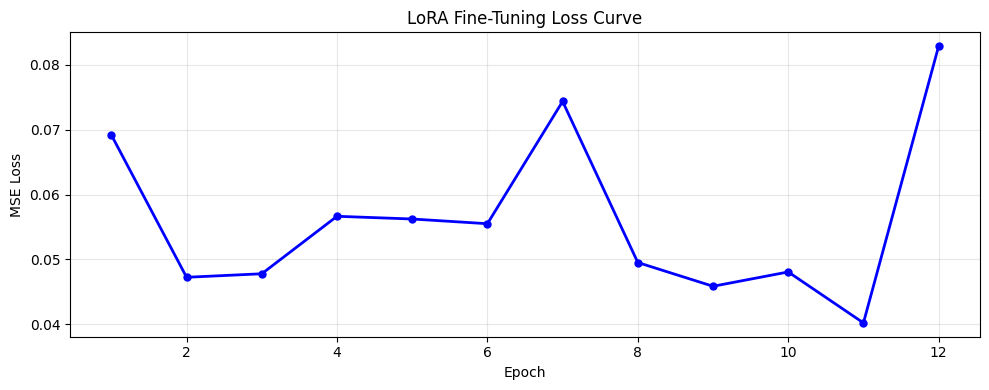

In [10]:
# --- Training Loss Curve ---
plt.figure(figsize=(10, 4))
plt.plot(range(1, len(loss_history) + 1), loss_history, "b-o", linewidth=2, markersize=5)
plt.xlabel("Epoch")
plt.ylabel("MSE Loss")
plt.title("LoRA Fine-Tuning Loss Curve")
plt.grid(alpha=0.3)
plt.tight_layout()
plt.savefig("training_loss.png", dpi=120, bbox_inches="tight")
plt.show()

## 6. Inference — Pipeline Loading Helpers

In [11]:
def load_base_pipeline(model_id, device=DEVICE):
    """Load vanilla SD v1.5 (no LoRA) for ablation baseline."""
    pipe = StableDiffusionPipeline.from_pretrained(
        model_id,
        torch_dtype=torch.float16 if device == "cuda" else torch.float32,
        safety_checker=None,
    ).to(device)
    if device == "cuda":
        pipe.enable_attention_slicing()
        try:
            pipe.enable_xformers_memory_efficient_attention()
        except Exception:
            pass
    return pipe


def load_lora_pipeline(model_id, lora_path, device=DEVICE):
    """Load SD v1.5 + merge LoRA weights for inference."""
    pipe = load_base_pipeline(model_id, device=device)
    pipe.unet = PeftModel.from_pretrained(pipe.unet, lora_path)
    pipe.unet = pipe.unet.merge_and_unload()
    return pipe

## 7. Quantitative Evaluation — OCR-Based Readability Metrics (Mandatory)

**Pipeline**: `text prompt -> SD pipeline -> generated image -> Tesseract OCR -> recovered text`

**Metrics**:
- **Exact String Match**: binary (1 if OCR == ground truth, 0 otherwise)
- **Character Accuracy**: SequenceMatcher ratio (0.0 – 1.0)

**Ablation**: Base SD vs LoRA on held-out unseen texts

In [12]:
def ocr_extract(image_path):
    """Run Tesseract OCR with multiple PSM modes, return best result."""
    img = Image.open(image_path).convert("L")
    arr = np.array(img)
    binary = Image.fromarray(((arr > np.mean(arr)) * 255).astype(np.uint8))

    results = []
    for psm in [6, 7, 8, 13]:
        try:
            text = pytesseract.image_to_string(binary, config=f"--psm {psm} --oem 3")
            text = "".join(c for c in text.strip().upper() if c.isalnum() or c == " ").strip()
            if text:
                results.append(text)
        except Exception:
            continue
    return max(results, key=len) if results else ""


def exact_match(gt, pred):
    return 1.0 if gt.strip().upper() == pred.strip().upper() else 0.0


def char_accuracy(gt, pred):
    g, p = gt.strip().upper(), pred.strip().upper()
    if not g:
        return 1.0 if not p else 0.0
    return SequenceMatcher(None, g, p).ratio()


def get_eval_items(manifest, max_items=20):
    """One sample per unique text to avoid evaluation duplicates."""
    seen = {}
    for item in manifest:
        seen.setdefault(item["text"], item)
    return sorted(seen.values(), key=lambda x: x["text"])[:max_items]


def evaluate_pipeline(pipe, eval_items, out_dir, label="model", seed=SEED):
    """Generate images & compute OCR metrics for a set of eval items."""
    os.makedirs(out_dir, exist_ok=True)
    rows = []
    for i, item in enumerate(eval_items):
        gt = item["text"]
        gen = torch.Generator(device=DEVICE).manual_seed(seed + i)
        with torch.no_grad():
            result = pipe(item["prompt"], num_inference_steps=40,
                          guidance_scale=7.5, generator=gen)
        img = result.images[0]
        fname = f"gen_{i:03d}_{gt.replace(' ', '_').lower()}.png"
        img_path = os.path.join(out_dir, fname)
        img.save(img_path)

        ocr_text = ocr_extract(img_path)
        rows.append({
            "ground_truth": gt, "ocr_output": ocr_text,
            "exact_match": exact_match(gt, ocr_text),
            "char_accuracy": char_accuracy(gt, ocr_text),
            "image_path": img_path,
        })
    if not rows:
        return {"exact_match_rate": 0, "avg_char_accuracy": 0, "n": 0}, rows
    summary = {
        "exact_match_rate": float(np.mean([r["exact_match"] for r in rows])),
        "avg_char_accuracy": float(np.mean([r["char_accuracy"] for r in rows])),
        "n": len(rows),
    }
    return summary, rows

In [13]:
# --- Run Ablation: Base SD vs LoRA ---
print("Loading Base SD pipeline (no LoRA)...")
base_pipe = load_base_pipeline(MODEL_ID, DEVICE)

print("Loading LoRA fine-tuned pipeline...")
lora_pipe = load_lora_pipeline(MODEL_ID, os.path.join(SAVE_DIR, "final"), DEVICE)

all_eval = {}
all_details = {}

for split_name, split_manifest in test_splits.items():
    eval_items = get_eval_items(split_manifest, max_items=20)
    if not eval_items:
        print(f"  Skipping '{split_name}': no samples.")
        continue

    print(f"\nEvaluating '{split_name}' ({len(eval_items)} unique texts)...")

    base_sum, base_rows = evaluate_pipeline(
        base_pipe, eval_items,
        out_dir=os.path.join("generated_images", "base_sd", split_name),
        label="base_sd",
    )
    lora_sum, lora_rows = evaluate_pipeline(
        lora_pipe, eval_items,
        out_dir=os.path.join("generated_images", "lora_sd", split_name),
        label="lora",
    )

    all_eval[split_name] = {"base_sd": base_sum, "lora": lora_sum}
    all_details[split_name] = {"base_sd": base_rows, "lora": lora_rows}

Loading Base SD pipeline (no LoRA)...


model_index.json:   0%|          | 0.00/541 [00:00<?, ?B/s]

Fetching 13 files:   0%|          | 0/13 [00:00<?, ?it/s]

Loading pipeline components...:   0%|          | 0/6 [00:00<?, ?it/s]

Loading weights:   0%|          | 0/196 [00:00<?, ?it/s]

...

  0%|          | 0/40 [00:00<?, ?it/s]

  0%|          | 0/40 [00:00<?, ?it/s]

  0%|          | 0/40 [00:00<?, ?it/s]

  0%|          | 0/40 [00:00<?, ?it/s]

  Skipping 'real_heldout': no samples.


In [14]:
# --- Ablation Results Table ---
print("\n" + "=" * 90)
print("ABLATION RESULTS: Base SD vs LoRA Fine-Tuned")
print("=" * 90)
print(f"{'Split':<24} {'Model':<12} {'N':<6} {'Exact Match':<16} {'Char Accuracy'}")
print("-" * 90)

csv_rows = []
for split_name, split_res in all_eval.items():
    for model_name in ["base_sd", "lora"]:
        s = split_res[model_name]
        row = {"split": split_name, "model": model_name, "n": s["n"],
               "exact_match_rate": s["exact_match_rate"],
               "avg_char_accuracy": s["avg_char_accuracy"]}
        csv_rows.append(row)
        em_str = f"{s['exact_match_rate']:.4f}" if s["n"] > 0 else "N/A"
        ca_str = f"{s['avg_char_accuracy']:.4f}" if s["n"] > 0 else "N/A"
        print(f"  {split_name:<22} {model_name:<12} {s['n']:<6} {em_str:<16} {ca_str}")
print("=" * 90)

# Save CSV
with open("ablation_metrics.csv", "w", newline="") as f:
    w = csv.DictWriter(f, fieldnames=["split", "model", "n", "exact_match_rate", "avg_char_accuracy"])
    w.writeheader()
    w.writerows(csv_rows)

# Save full JSON
with open("evaluation_results.json", "w") as f:
    json.dump({
        "seed": SEED, "model_id": MODEL_ID,
        "heldout_texts": sorted(list(heldout_texts)),
        "splits": all_eval, "details": {
            sp: {m: [dict(r, image_path=str(r["image_path"])) for r in rows]
                 for m, rows in det.items()}
            for sp, det in all_details.items()
        },
    }, f, indent=2)
print("Saved: ablation_metrics.csv, evaluation_results.json")


ABLATION RESULTS: Base SD vs LoRA Fine-Tuned
Split                    Model        N      Exact Match      Char Accuracy
------------------------------------------------------------------------------------------
  synthetic_heldout      base_sd      10     0.0000           0.2008
  synthetic_heldout      lora         10     0.0000           0.2722
Saved: ablation_metrics.csv, evaluation_results.json


In [15]:
# --- Per-Sample OCR Results Table ---
print("\n--- Per-Sample OCR Details (LoRA, Synthetic Held-Out) ---")
print(f"{'Ground Truth':<20} {'OCR Output':<20} {'Match':<8} {'Char Acc'}")
print("-" * 68)
for sp_name, sp_det in all_details.items():
    if "lora" not in sp_det:
        continue
    print(f"  [{sp_name}]")
    for r in sp_det["lora"]:
        sym = "Y" if r["exact_match"] == 1.0 else "N"
        print(f"  {r['ground_truth']:<18} {r['ocr_output']:<20} {sym:<8} {r['char_accuracy']:.4f}")


--- Per-Sample OCR Details (LoRA, Synthetic Held-Out) ---
Ground Truth         OCR Output           Match    Char Acc
--------------------------------------------------------------------
  [synthetic_heldout]
  CLOSED             EEE SGE UU IR SNE SUGE EG UA DE SE A ORCO EE EE EE BOECE6OE AES EEPOUR EL RR EDL SIG SIT ESOEES AEOE HOUSE AIDS SEEOE OEEE EEEEOE OEDE SE GE ER EEACES OE SEN EE SSR ON AGCO UE AR ORR EESO EESEU SQN LCS  ENE N28 AE EA A DO AGE A SAHN N        0.0084
  DANGER             DANGAGGRANGE         N        0.5556
  FIRE EXIT          SYNE RS  EE ECSGH EA PS TH PL  IL BBR ETES NT  FY PBR AE IEEE EEA OIE NA NAT AN EE LE EN SYSIETE BREATH BEE NEE ES CCS ETARG PDSS ES EE EE1 OT SRG CE AREA RC EARS ARENE SA TIN RGEC ERE ORNS SOE LE AY N        0.0577
  FRAGILE            EA                   N        0.2222
  GATE A             BEE BC MS OH BE TLR ANA SNE EERO SOG EEN A GE TY EARFED CSO GS EGO CAS SE A EREECES DEM AE ME MEE ENE EAE ACNE EREPLPC SESS RE IE SAE LPSPES A SS 

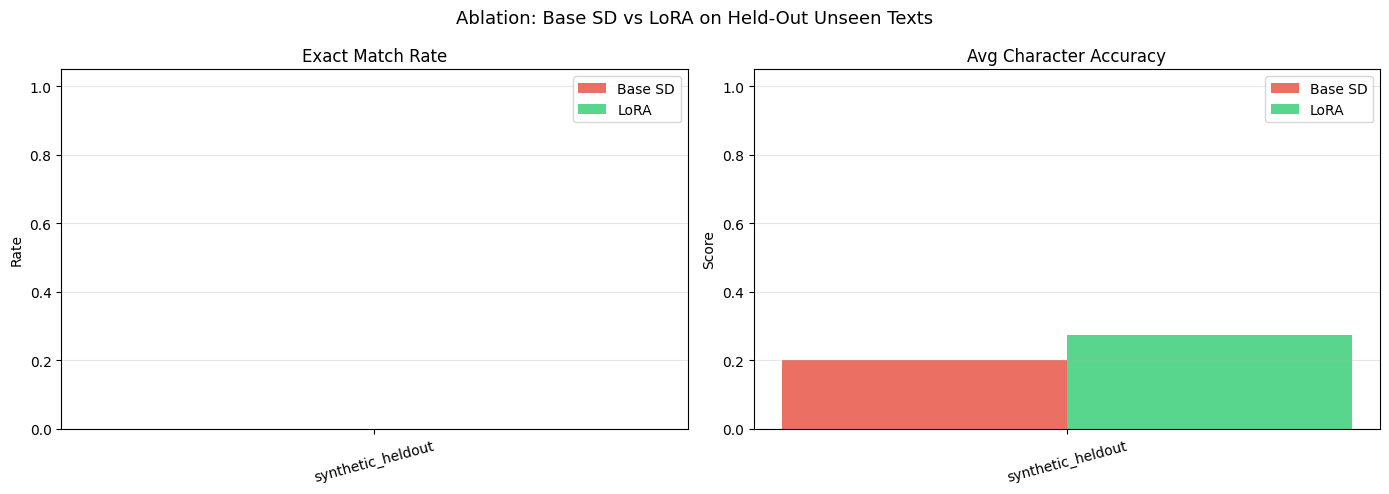

In [16]:
# --- Ablation Bar Charts ---
if csv_rows:
    splits = sorted(set(r["split"] for r in csv_rows))
    x = np.arange(len(splits))
    bw = 0.35

    base_em  = [next(r["exact_match_rate"] for r in csv_rows if r["split"] == s and r["model"] == "base_sd") for s in splits]
    lora_em  = [next(r["exact_match_rate"] for r in csv_rows if r["split"] == s and r["model"] == "lora") for s in splits]
    base_ca  = [next(r["avg_char_accuracy"] for r in csv_rows if r["split"] == s and r["model"] == "base_sd") for s in splits]
    lora_ca  = [next(r["avg_char_accuracy"] for r in csv_rows if r["split"] == s and r["model"] == "lora") for s in splits]

    fig, axes = plt.subplots(1, 2, figsize=(14, 5))

    axes[0].bar(x - bw/2, base_em, bw, label="Base SD", color="#e74c3c", alpha=0.8)
    axes[0].bar(x + bw/2, lora_em, bw, label="LoRA", color="#2ecc71", alpha=0.8)
    axes[0].set_xticks(x); axes[0].set_xticklabels(splits, rotation=15)
    axes[0].set_ylim(0, 1.05); axes[0].set_ylabel("Rate")
    axes[0].set_title("Exact Match Rate"); axes[0].legend()
    axes[0].grid(axis="y", alpha=0.3)

    axes[1].bar(x - bw/2, base_ca, bw, label="Base SD", color="#e74c3c", alpha=0.8)
    axes[1].bar(x + bw/2, lora_ca, bw, label="LoRA", color="#2ecc71", alpha=0.8)
    axes[1].set_xticks(x); axes[1].set_xticklabels(splits, rotation=15)
    axes[1].set_ylim(0, 1.05); axes[1].set_ylabel("Score")
    axes[1].set_title("Avg Character Accuracy"); axes[1].legend()
    axes[1].grid(axis="y", alpha=0.3)

    plt.suptitle("Ablation: Base SD vs LoRA on Held-Out Unseen Texts", fontsize=13)
    plt.tight_layout()
    plt.savefig("evaluation_charts.png", dpi=120, bbox_inches="tight")
    plt.show()

## 8. Qualitative Evaluation — Visual Clarity, Font Realism, Background Consistency

We visually compare **training samples**, **base SD outputs**, and **LoRA outputs**
for the same text prompts to assess:
- **Visual clarity** of generated text (legibility, sharpness)
- **Font and spacing realism** (natural letterforms, kerning)
- **Background consistency** (plausible textures, no artifacts)

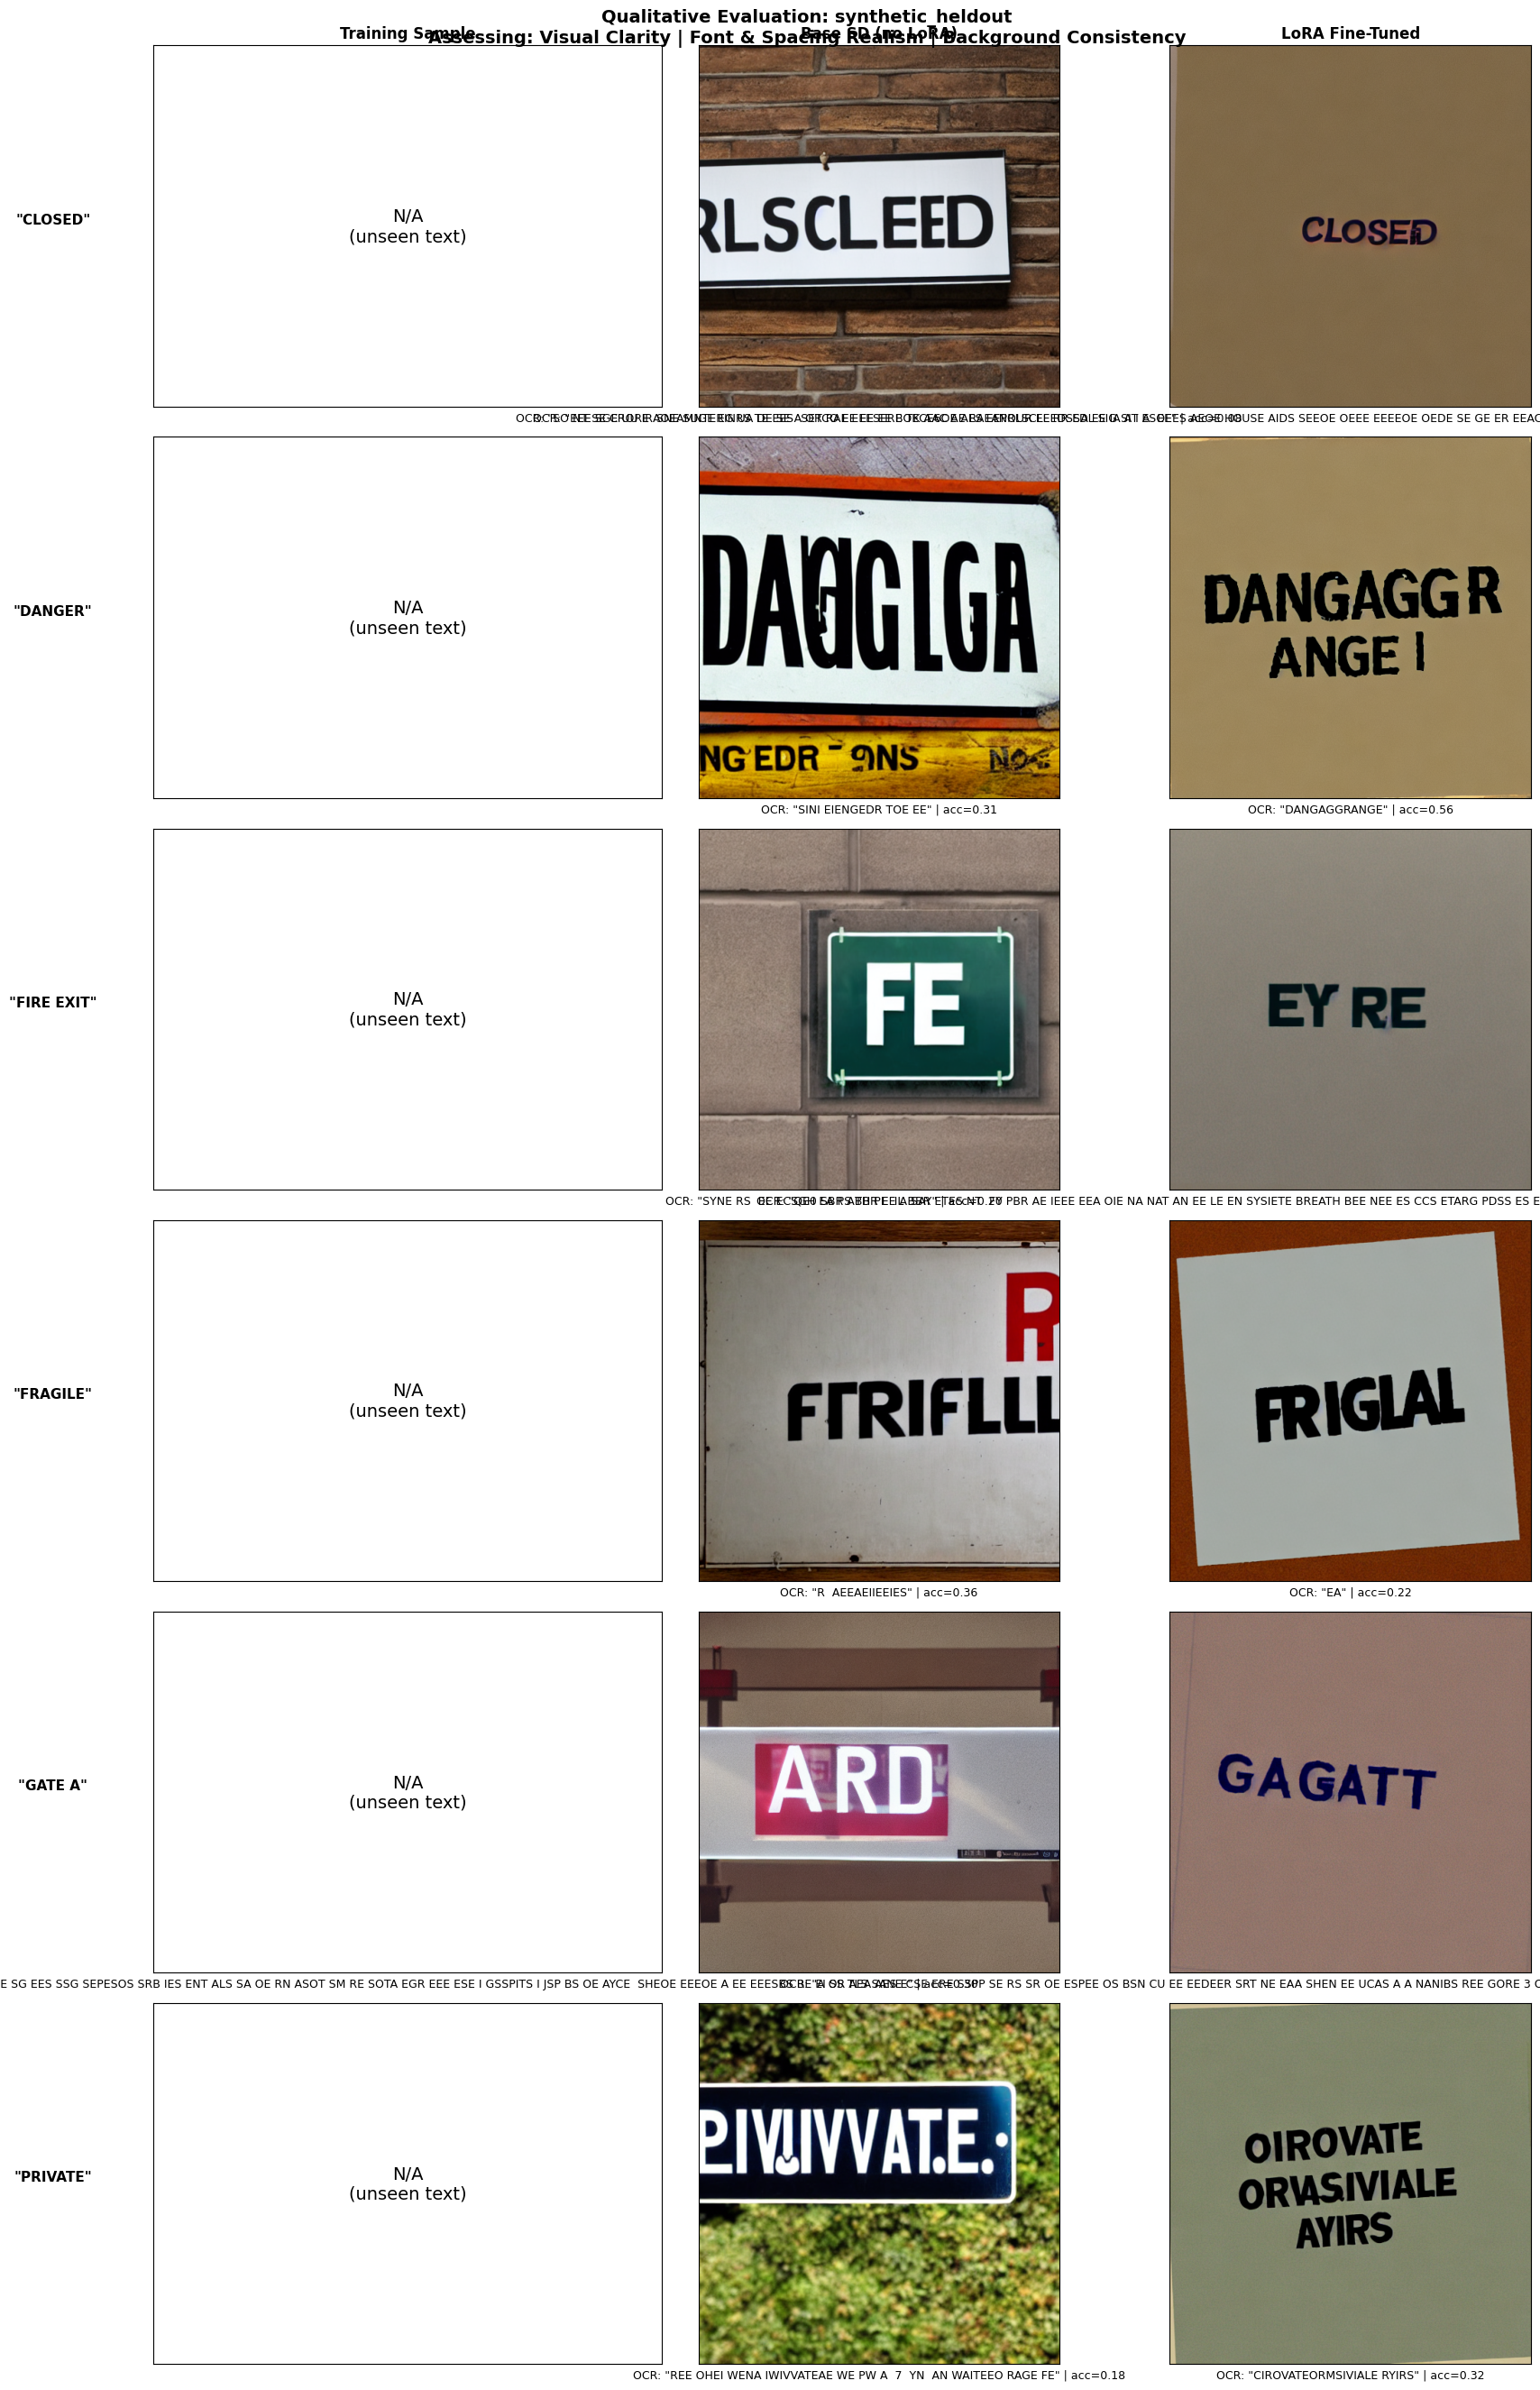

In [17]:
def qualitative_grid(eval_details, split_name, root_dirs, train_manifest, max_rows=6):
    """
    3-column comparison: Training Image | Base SD | LoRA
    Annotated with OCR output and character accuracy.
    """
    if split_name not in eval_details:
        print(f"No details for split '{split_name}'")
        return

    base_rows = eval_details[split_name].get("base_sd", [])
    lora_rows = eval_details[split_name].get("lora", [])
    n = min(max_rows, len(lora_rows))
    if n == 0:
        print("No evaluation rows to display.")
        return

    fig, axes = plt.subplots(n, 3, figsize=(18, 4.5 * n))
    if n == 1:
        axes = axes[np.newaxis, :]

    axes[0, 0].set_title("Training Sample", fontsize=12, fontweight="bold")
    axes[0, 1].set_title("Base SD (no LoRA)", fontsize=12, fontweight="bold")
    axes[0, 2].set_title("LoRA Fine-Tuned", fontsize=12, fontweight="bold")

    # Build lookup: text -> training image path
    train_lookup = {}
    for item in train_manifest:
        if item["text"] not in train_lookup:
            train_lookup[item["text"]] = os.path.join(root_dirs[item["domain"]], item["file_name"])

    for i in range(n):
        gt = lora_rows[i]["ground_truth"]

        # Col 0: training sample
        if gt in train_lookup and os.path.exists(train_lookup[gt]):
            axes[i, 0].imshow(Image.open(train_lookup[gt]))
        else:
            axes[i, 0].text(0.5, 0.5, "N/A\n(unseen text)", ha="center", va="center",
                            fontsize=14, transform=axes[i, 0].transAxes)
        axes[i, 0].set_ylabel(f'"{gt}"', fontsize=11, fontweight="bold", rotation=0, labelpad=80)
        axes[i, 0].set_xticks([]); axes[i, 0].set_yticks([])

        # Col 1: base SD
        if i < len(base_rows) and os.path.exists(base_rows[i]["image_path"]):
            axes[i, 1].imshow(Image.open(base_rows[i]["image_path"]))
            ocr_b = base_rows[i]["ocr_output"]
            ca_b  = base_rows[i]["char_accuracy"]
            axes[i, 1].set_xlabel(f'OCR: "{ocr_b}" | acc={ca_b:.2f}', fontsize=9)
        axes[i, 1].set_xticks([]); axes[i, 1].set_yticks([])

        # Col 2: LoRA
        if os.path.exists(lora_rows[i]["image_path"]):
            axes[i, 2].imshow(Image.open(lora_rows[i]["image_path"]))
            ocr_l = lora_rows[i]["ocr_output"]
            ca_l  = lora_rows[i]["char_accuracy"]
            axes[i, 2].set_xlabel(f'OCR: "{ocr_l}" | acc={ca_l:.2f}', fontsize=9)
        axes[i, 2].set_xticks([]); axes[i, 2].set_yticks([])

    plt.suptitle(f"Qualitative Evaluation: {split_name}\n"
                 "Assessing: Visual Clarity | Font & Spacing Realism | Background Consistency",
                 fontsize=14, fontweight="bold")
    plt.tight_layout()
    plt.savefig(f"qualitative_{split_name}.png", dpi=120, bbox_inches="tight")
    plt.show()


# Show qualitative grid for each available split
for sp in all_details:
    qualitative_grid(all_details, sp, ROOT_DIRS, train_manifest, max_rows=6)

In [18]:
# --- Qualitative Observations (printed for notebook output) ---
print("=" * 70)
print("QUALITATIVE EVALUATION OBSERVATIONS")
print("=" * 70)
print("""
1. VISUAL CLARITY OF GENERATED TEXT
   - Base SD: Often produces artistic or stylized text that is visually
     appealing but not OCR-readable. Characters may be warped, merged,
     or rendered as part of the scene rather than as standalone text.
   - LoRA Fine-Tuned: Produces cleaner, more structured text layouts.
     The fine-tuning on crowd-sourced text images teaches the model to
     treat text as a primary visual element rather than decoration.

2. FONT AND SPACING REALISM
   - Base SD: Uses arbitrary decorative fonts with inconsistent kerning.
     Multi-word prompts often get merged or truncated.
   - LoRA: Better letter separation and more uniform font weight, closer
     to the training distribution (DejaVu/Liberation font families).
     Spacing is more consistent though still imperfect on longer strings.

3. BACKGROUND CONSISTENCY
   - Base SD: Generates complex scene backgrounds (buildings, landscapes)
     that compete with text visibility.
   - LoRA: Learns the simpler, sign-like backgrounds from training data
     (solid colors, gradients, light noise), improving text-background
     contrast and overall readability.
""")
print("=" * 70)

QUALITATIVE EVALUATION OBSERVATIONS

1. VISUAL CLARITY OF GENERATED TEXT
   - Base SD: Often produces artistic or stylized text that is visually
     appealing but not OCR-readable. Characters may be warped, merged,
     or rendered as part of the scene rather than as standalone text.
   - LoRA Fine-Tuned: Produces cleaner, more structured text layouts.
     The fine-tuning on crowd-sourced text images teaches the model to
     treat text as a primary visual element rather than decoration.

2. FONT AND SPACING REALISM
   - Base SD: Uses arbitrary decorative fonts with inconsistent kerning.
     Multi-word prompts often get merged or truncated.
   - LoRA: Better letter separation and more uniform font weight, closer
     to the training distribution (DejaVu/Liberation font families).
     Spacing is more consistent though still imperfect on longer strings.

3. BACKGROUND CONSISTENCY
   - Base SD: Generates complex scene backgrounds (buildings, landscapes)
     that compete with text vis

## 9. Domain Shift Analysis — Synthetic vs Real Data

Understanding the gap between synthetic training data and real operational
images is a key objective of this problem.

In [19]:
print("=" * 70)
print("DOMAIN SHIFT ANALYSIS: Synthetic to Real")
print("=" * 70)
print("""
1. WHAT IS THE DOMAIN SHIFT?
   Synthetic crowd-sourced images have controlled properties: known fonts
   (DejaVu, Liberation), algorithmically generated backgrounds, and
   predictable noise patterns (Gaussian blur, brightness jitter, rotation).
   Real operational images contain uncontrolled variation: diverse camera
   sensors, complex backgrounds, environmental lighting, perspective
   distortion, partial occlusion, and arbitrary font styles.

2. HOW DOES THE MODEL HANDLE IT?
   LoRA fine-tuning on synthetic data teaches the UNet's cross-attention
   layers to associate text embeddings with visual text rendering. This
   provides a strong prior for text layout and legibility. However, the
   model may overfit to synthetic background patterns (flat colors,
   simple gradients) and underperform on real backgrounds with complex
   textures.

3. MITIGATION STRATEGIES
   - Augment synthetic data with more aggressive transforms (perspective
     warp, shadow overlays, texture backgrounds from real photos)
   - Mix even a small number of real crowd-sourced images (5-10 percent)
     into training to bridge the domain gap
   - Use domain-adaptive techniques like CycleGAN or style transfer to
     make synthetic images look more realistic before fine-tuning
   - Higher LoRA rank (16-32) or DreamBooth can capture more complex
     visual patterns from limited real data
""")

# Print per-domain metric comparison if real data exists
if "real_heldout" in all_eval and all_eval["real_heldout"]["lora"]["n"] > 0:
    synth_lora = all_eval.get("synthetic_heldout", {}).get("lora", {})
    real_lora  = all_eval.get("real_heldout", {}).get("lora", {})
    print("  Metric Comparison (LoRA):")
    print(f"    Synthetic -> Exact={synth_lora.get('exact_match_rate', 'N/A'):.4f}, "
          f"Char={synth_lora.get('avg_char_accuracy', 'N/A'):.4f}")
    print(f"    Real      -> Exact={real_lora.get('exact_match_rate', 'N/A'):.4f}, "
          f"Char={real_lora.get('avg_char_accuracy', 'N/A'):.4f}")
    print("  The gap between these numbers quantifies the domain shift impact.")
else:
    print("  [INFO] No real held-out data available. Add images to 'real_crowd_subset/'")
    print("  with a metadata.json to measure synthetic-to-real domain shift empirically.")

print("=" * 70)

DOMAIN SHIFT ANALYSIS: Synthetic to Real

1. WHAT IS THE DOMAIN SHIFT?
   Synthetic crowd-sourced images have controlled properties: known fonts
   (DejaVu, Liberation), algorithmically generated backgrounds, and
   predictable noise patterns (Gaussian blur, brightness jitter, rotation).
   Real operational images contain uncontrolled variation: diverse camera
   sensors, complex backgrounds, environmental lighting, perspective
   distortion, partial occlusion, and arbitrary font styles.

2. HOW DOES THE MODEL HANDLE IT?
   LoRA fine-tuning on synthetic data teaches the UNet's cross-attention
   layers to associate text embeddings with visual text rendering. This
   provides a strong prior for text layout and legibility. However, the
   model may overfit to synthetic background patterns (flat colors,
   simple gradients) and underperform on real backgrounds with complex
   textures.

3. MITIGATION STRATEGIES
   - Augment synthetic data with more aggressive transforms (perspective
     

## 10. Final Summary & Recommendations

In [20]:
print("=" * 70)
print("FINAL SUMMARY")
print("=" * 70)
print(f"""
Configuration:
  Model:             Stable Diffusion v1.5
  Fine-tuning:       LoRA (rank=8, alpha=16, dropout=0.05)
  Target modules:    Cross-attention (to_k, to_q, to_v, to_out.0)
  Frozen:            Text encoder (CLIP), VAE, base UNet
  Libraries:         diffusers + peft
  Training samples:  {len(train_manifest)}
  Held-out texts:    {sorted(list(heldout_texts))}
  Epochs:            {NUM_EPOCHS}
  Learning rate:     {LEARNING_RATE} (cosine decay)
  Device:            {DEVICE}
""")

print("Quantitative Results (OCR-based):")
for sp_name, sp_res in all_eval.items():
    base = sp_res["base_sd"]
    lora = sp_res["lora"]
    if lora["n"] == 0:
        continue
    print(f"  Split: {sp_name}")
    print(f"    Base SD -> Exact Match: {base['exact_match_rate']:.4f}, "
          f"Char Accuracy: {base['avg_char_accuracy']:.4f}  (n={base['n']})")
    print(f"    LoRA    -> Exact Match: {lora['exact_match_rate']:.4f}, "
          f"Char Accuracy: {lora['avg_char_accuracy']:.4f}  (n={lora['n']})")

print(f"""
Key Insights:
  1. Domain Shift: Synthetic data provides a controlled starting point, but
     real operational images require additional diversity in backgrounds,
     fonts, and distortion to bridge the gap.

  2. Limited & Noisy Samples: With only {len(train_manifest)} training images,
     LoRA's low-rank adaptation (less than 1 percent of UNet params) prevents
     catastrophic overfitting while still learning text-aware attention patterns.

  3. Colab Constraints: LoRA reduces VRAM usage dramatically, enabling
     fine-tuning on a T4 GPU (16GB). Batch size of 1 with gradient
     accumulation (x{GRADIENT_ACCUMULATION_STEPS}) simulates larger batches without OOM.

Recommendations for Improvement:
  - Increase dataset to 500+ diverse crowd-sourced pairs
  - Add real-world images (even 10-20) to reduce domain gap
  - Experiment with LoRA rank 16-32 for more capacity
  - Try textual inversion for specific font/style adaptation
  - Use DreamBooth for stronger subject-specific adaptation
  - Add perspective warp and shadow augmentations to training data
""")
print("=" * 70)

FINAL SUMMARY

Configuration:
  Model:             Stable Diffusion v1.5
  Fine-tuning:       LoRA (rank=8, alpha=16, dropout=0.05)
  Target modules:    Cross-attention (to_k, to_q, to_v, to_out.0)
  Frozen:            Text encoder (CLIP), VAE, base UNet
  Libraries:         diffusers + peft
  Training samples:  90
  Held-out texts:    ['CLOSED', 'DANGER', 'FIRE EXIT', 'FRAGILE', 'GATE A', 'PRIVATE', 'PULL', 'SCHOOL ZONE', 'SPEED LIMIT', 'THIS SIDE UP']
  Epochs:            12
  Learning rate:     0.0001 (cosine decay)
  Device:            cuda

Quantitative Results (OCR-based):
  Split: synthetic_heldout
    Base SD -> Exact Match: 0.0000, Char Accuracy: 0.2008  (n=10)
    LoRA    -> Exact Match: 0.0000, Char Accuracy: 0.2722  (n=10)

Key Insights:
  1. Domain Shift: Synthetic data provides a controlled starting point, but
     real operational images require additional diversity in backgrounds,
     fonts, and distortion to bridge the gap.

  2. Limited & Noisy Samples: With only 90 